# Разведочный анализ данных: карточки, клики, каталог

Данные — архив организаторов `dataset.zip` (SHA-256 в `brief/sources/README.md`), распакованный в
`data/raw/`. Три файла:

| Файл | Что внутри |
|---|---|
| `sku_desc.parquet` | Текст карточки: `sku_id`, `title`, `description` |
| `query_clicks.parquet` | Клики из поиска: SKU, текст запроса, позиция, категория, цена |
| `skus.pkl` | Выгрузка YML-каталога: категории и офферы с параметрами, в том числе `*_search` |

Вопросы, на которые отвечает ноутбук: насколько полны и чисты текстовые поля; как распределён
трафик по товарам и категориям; насколько велик длинный хвост; сколько характеристик уже лежит в
описании в виде «ключ: значение»; как часто одно значение записано по-разному.

Запуск: `uvx --with pandas --with pyarrow --with matplotlib --with ipykernel --with nbconvert
jupytext --to ipynb --execute notebooks/eda.py`.

In [1]:
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIG = ROOT / "docs" / "images" / "eda"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")

## 1. Обзор файлов

In [2]:
overview = []
for name in ["sku_desc.parquet", "query_clicks.parquet"]:
    meta = pq.ParquetFile(RAW / name).metadata
    overview.append({"файл": name, "строк": meta.num_rows, "колонок": meta.num_columns,
                     "МБ на диске": round((RAW / name).stat().st_size / 2**20, 1)})
overview.append({"файл": "skus.pkl", "строк": None, "колонок": None,
                 "МБ на диске": round((RAW / "skus.pkl").stat().st_size / 2**20, 1)})
pd.DataFrame(overview)

,файл,строк,колонок,МБ на диске
0,sku_desc.parquet,1177200.0,3.0,335.8
1,query_clicks.parquet,30991350.0,8.0,620.7
2,skus.pkl,NaN,NaN,1492.6


## 2. Карточки: `sku_desc.parquet`

In [3]:
desc_file = pq.ParquetFile(RAW / "sku_desc.parquet")
n_desc = desc_file.metadata.num_rows
flags = {
    "title пустой или null": ("title", None),
    "description пустой или null": ("description", None),
    "description короче 50 символов": ("description", None),
    "в description есть блок «Характеристики:»": ("description", r"Характеристики:"),
    "в description есть строки «• ключ: значение»": ("description", r"•\s*[^:\n]{2,60}:\s*\S"),
    "в description есть HTML-теги": ("description", r"<\s*/?\s*(br|p|li|ul|b|div)\b"),
    "title заканчивается на « -» (пустая модель)": ("title", r"\s-\s*$"),
    "уценённый товар": ("title", r"(?i)^уцен"),
}
counts = Counter()
title_lens, body_lens = [], []
rng = np.random.default_rng(42)
sample_body = []
SAMPLE_RATE = 200_000 / n_desc


def count_true(mask):
    return pc.sum(pc.cast(pc.fill_null(mask, False), pa.int64())).as_py() or 0


for batch in desc_file.iter_batches(columns=["title", "description"], batch_size=100_000):
    title, body = batch.column(0), batch.column(1)
    tl = pc.fill_null(pc.utf8_length(title), 0)
    bl = pc.fill_null(pc.utf8_length(body), 0)
    title_lens.append(tl.to_numpy(zero_copy_only=False))
    body_lens.append(bl.to_numpy(zero_copy_only=False))
    counts["title пустой или null"] += count_true(pc.equal(tl, 0))
    counts["description пустой или null"] += count_true(pc.equal(bl, 0))
    counts["description короче 50 символов"] += count_true(pc.less(bl, 50))
    for name, (col, rx) in flags.items():
        if rx:
            counts[name] += count_true(pc.match_substring_regex(title if col == "title" else body, rx))
    take = np.flatnonzero(rng.random(len(body)) < SAMPLE_RATE)
    sample_body.extend(body.take(pa.array(take)).to_pylist())
    del title, body, batch

title_len, body_len = np.concatenate(title_lens), np.concatenate(body_lens)
desc_ids = pc.unique(pq.read_table(RAW / "sku_desc.parquet", columns=["sku_id"])["sku_id"])
print(f"Карточек: {n_desc:,}; дублей sku_id: {n_desc - len(desc_ids):,}")
quality = pd.DataFrame([{"признак": k, "% карточек": round(counts[k] / n_desc * 100, 2)} for k in flags])
quality

Карточек: 1,177,200; дублей sku_id: 0


,признак,% карточек
0,title пустой или null,0.00
1,description пустой или null,0.00
2,description короче 50 символов,0.18
3,в description есть блок «Характеристики:»,28.64
4,в description есть строки «• ключ: значение»,30.16
5,в description есть HTML-теги,49.31
6,title заканчивается на « -» (пустая модель),26.08
7,уценённый товар,2.81


**Вывод.** Пропуски и мусор в тексте — первое, что видит пайплайн; доля блока «Характеристики:»
определяет, сколько атрибутов закроет простой парсер «ключ: значение», и поэтому метрики считаются
в двух режимах: с этим блоком и с вырезанным.

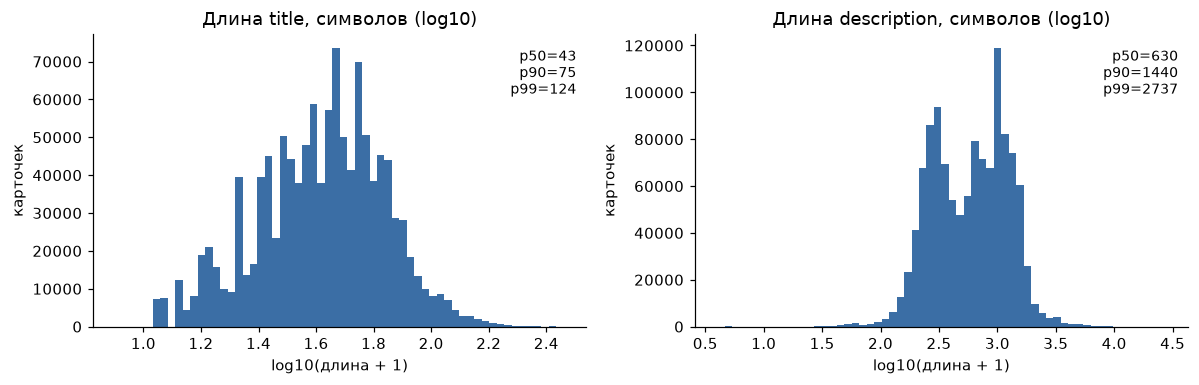

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, arr, label in [(axes[0], title_len, "title"), (axes[1], body_len, "description")]:
    ax.hist(np.log10(arr + 1), bins=60, color="#3b6ea5")
    ax.set_title(f"Длина {label}, символов (log10)")
    ax.set_xlabel("log10(длина + 1)")
    ax.set_ylabel("карточек")
    q = np.percentile(arr, [50, 90, 99])
    ax.text(0.98, 0.95, f"p50={q[0]:.0f}\np90={q[1]:.0f}\np99={q[2]:.0f}", transform=ax.transAxes,
            ha="right", va="top", fontsize=9)
save(fig, "text_length")

### Какие ключи встречаются в строках «ключ: значение»

Случайная выборка ~200 тысяч описаний. Ключи — кандидаты в атрибуты, а разнобой в их записи
показывает, сколько нормализации нужно уже на уровне названий атрибутов.

In [5]:
kv = re.compile(r"(?:^|\n)[ \t]*[•\-–]?[ \t]*([А-ЯЁA-Z][^:\n]{1,50}?)[ \t]*:[ \t]*([^\n]{1,80})")
keys, pairs = Counter(), Counter()
for text in sample_body:
    if not text:
        continue
    for k, v in kv.findall(text):
        k = k.strip().lower()
        keys[k] += 1
        pairs[(k, v.strip().lower())] += 1
top_keys = pd.DataFrame(keys.most_common(30), columns=["ключ", "карточек в выборке"])
top_keys

,ключ,карточек в выборке
0,цвет,27279
1,материал,23280
2,назначение,18434
3,тип,15007
4,страна происхождения,11734
5,модель,10459
6,внешний вид,9576
7,применение,7777
8,стиль,7721
9,возраст,6577


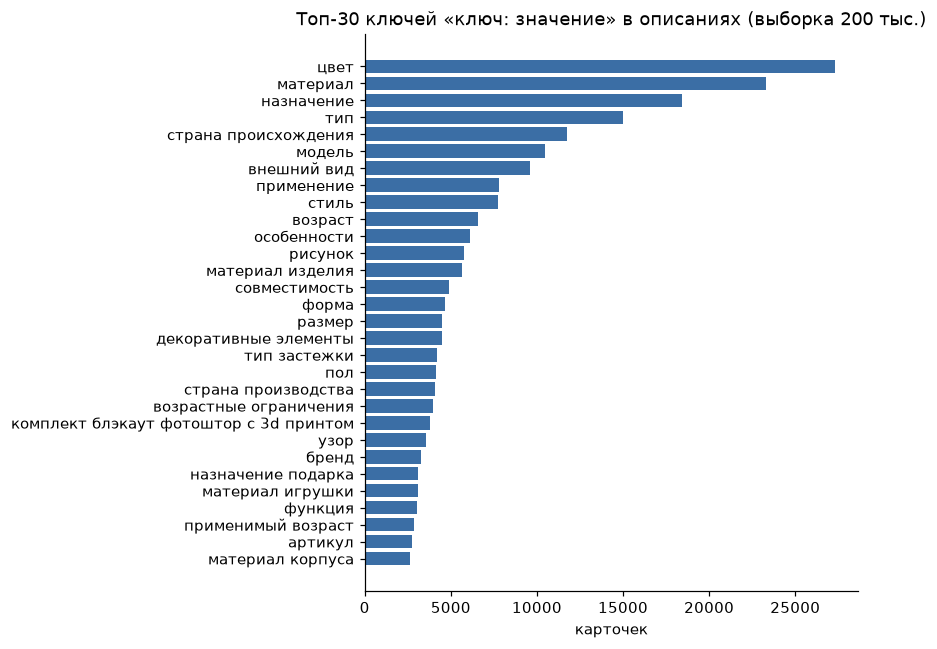

In [6]:
fig, ax = plt.subplots(figsize=(8, 6))
tk = top_keys.iloc[::-1]
ax.barh(tk["ключ"], tk["карточек в выборке"], color="#3b6ea5")
ax.set_title("Топ-30 ключей «ключ: значение» в описаниях (выборка 200 тыс.)")
ax.set_xlabel("карточек")
save(fig, "top_description_keys")

### Одно значение — много записей

Значения ключа «цвет» в той же выборке: сколько разных строк описывают несколько базовых цветов.

In [7]:
colors = Counter()
for (k, v), c in pairs.items():
    if k.startswith("цвет"):
        colors[v] += c
base = ["черн", "бел", "красн", "син", "сер", "зел"]
variants = {b: sorted([(v, c) for v, c in colors.items() if b in v], key=lambda x: -x[1]) for b in base}
pd.DataFrame([{"базовый цвет": b, "разных записей": len(vs),
               "примеры": ", ".join(v for v, _ in vs[:8])} for b, vs in variants.items()])

,базовый цвет,разных записей,примеры
0,черн,142,"черный, черный матовый, черный., черный, белый, матовый черный, черное, черный, красный, синий, черный фон"
1,бел,149,"белый, чёрный, белый, розовый, бирюзовый, ультрамарин., молочно-белый, чёрный титан, натуральный титан, белый титан,..."
2,красн,97,"красный, ярко-красный, темно-красный, винно-красный, винный красный, черный, красный, синий, красно-белый, красно-синий"
3,син,126,"синий, темно-синий, светло-синий, ярко-синий, тёмно-синий, королевский синий, ледяной синий, синий."
4,сер,130,"серый, серебристый, темно-серый, серебро, светло-серый, серебряный, тёмно-серый, серебристый, чёрный космос."
5,зел,112,"зеленый, темно-зеленый, ярко-зеленый, зелёный, светло-зеленый, тёмно-зелёный, яркий зеленый, ярко-зелёный"


**Вывод.** Даже внутри одного ключа значения записаны десятками способов — справочник канонических
значений с алиасами обязателен до любой модели.

In [8]:
del sample_body, title_lens, body_lens

## 3. Клики: `query_clicks.parquet`

In [9]:
qc_file = pq.ParquetFile(RAW / "query_clicks.parquet")
cols = qc_file.schema_arrow.names
Q, NAME, BRAND = "toValidUTF8(query_text)", "toValidUTF8(sku_name)", "toValidUTF8(sku_brand_name)"
qc_parts, seo_ids = [], set()
for batch in qc_file.iter_batches(columns=["sku_id", "sku_subject_id", "sku_seo_id", "sku_position"],
                                  batch_size=2_000_000):
    qc_parts.append(pa.table({
        "sku_id": pc.cast(batch.column(0), pa.int64()),
        "sku_subject_id": pc.cast(batch.column(1), pa.int32()),
        "sku_position": pc.cast(batch.column(3), pa.int32()),
    }))
    seo_ids.update(pc.unique(batch.column(2)).to_pylist())
qc = pa.concat_tables(qc_parts)
del qc_parts
n_clicks = qc.num_rows
sku_clicks = qc.group_by("sku_id").aggregate([("sku_id", "count")]).rename_columns(["sku_id", "clicks"])
cat_clicks = qc.group_by("sku_subject_id").aggregate([("sku_id", "count"), ("sku_id", "count_distinct")])
cat_clicks = cat_clicks.rename_columns(["subject_id", "clicks", "skus"])
print(f"Кликов: {n_clicks:,}; уникальных SKU: {sku_clicks.num_rows:,}; "
      f"категорий (sku_subject_id): {cat_clicks.num_rows:,}; "
      f"seo-категорий: {len(seo_ids):,}")

Кликов: 30,991,350; уникальных SKU: 332,753; категорий (sku_subject_id): 4,103; seo-категорий: 4,101


In [10]:
empty = Counter()
for batch in qc_file.iter_batches(columns=[NAME, BRAND, Q], batch_size=2_000_000):
    for i, col in enumerate([NAME, BRAND, Q]):
        empty[col] += count_true(pc.equal(pc.fill_null(pc.utf8_length(batch.column(i)), 0), 0))
empty = {k: round(v / n_clicks * 100, 2) for k, v in empty.items()}
pd.DataFrame([{"колонка": k, "% пустых": v} for k, v in empty.items()])

,колонка,% пустых
0,toValidUTF8(sku_name),21.75
1,toValidUTF8(sku_brand_name),28.37
2,toValidUTF8(query_text),0.00


### Концентрация трафика

Кривая показывает, какая доля SKU собирает какую долю кликов. Чем круче кривая, тем сильнее
взвешивание по трафику расходится с простым средним по карточкам.

Медиана кликов на SKU: 7; SKU с одним кликом: 21.5%


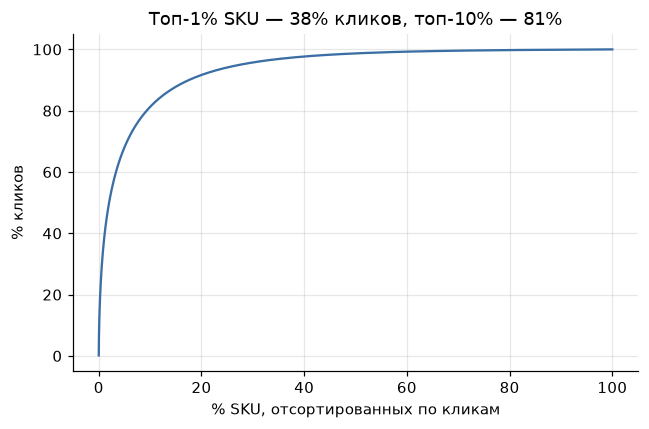

In [11]:
c = np.sort(sku_clicks["clicks"].to_numpy())[::-1]
cum = np.cumsum(c) / c.sum()
x = np.arange(1, len(c) + 1) / len(c)
top1, top10 = cum[int(len(c) * 0.01) - 1], cum[int(len(c) * 0.10) - 1]
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(x * 100, cum * 100, color="#3b6ea5")
ax.set_xlabel("% SKU, отсортированных по кликам")
ax.set_ylabel("% кликов")
ax.set_title(f"Топ-1% SKU — {top1:.0%} кликов, топ-10% — {top10:.0%}")
ax.grid(alpha=0.3)
save(fig, "traffic_concentration")
print(f"Медиана кликов на SKU: {np.median(c):.0f}; SKU с одним кликом: {(c == 1).mean():.1%}")

Топ-50 категорий — 70% кликов; категорий с < 100 кликами: 2,341


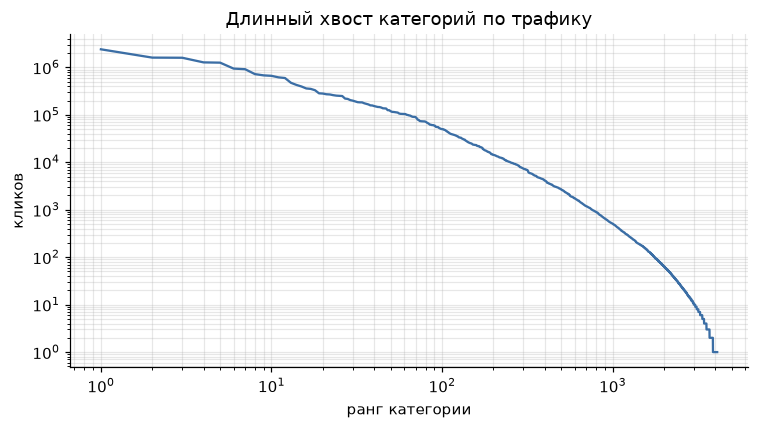

In [12]:
cc = cat_clicks.to_pandas().sort_values("clicks", ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(np.arange(1, len(cc) + 1), cc["clicks"], color="#3b6ea5")
ax.set_xlabel("ранг категории")
ax.set_ylabel("кликов")
ax.set_title("Длинный хвост категорий по трафику")
ax.grid(alpha=0.3, which="both")
save(fig, "category_long_tail")
head_share = cc["clicks"].head(50).sum() / cc["clicks"].sum()
print(f"Топ-50 категорий — {head_share:.0%} кликов; категорий с < 100 кликами: {(cc['clicks'] < 100).sum():,}")

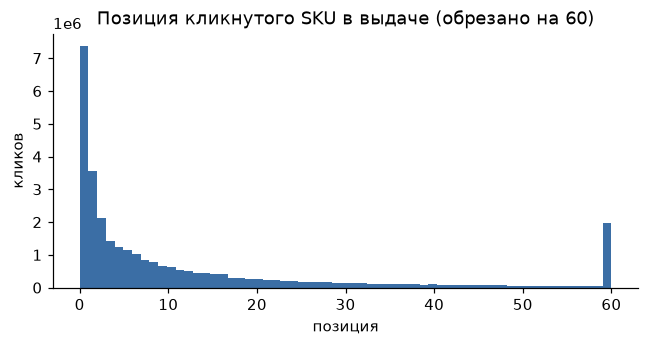

In [13]:
pos = qc["sku_position"].to_numpy()
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.hist(np.clip(pos, 0, 60), bins=61, color="#3b6ea5")
ax.set_title("Позиция кликнутого SKU в выдаче (обрезано на 60)")
ax.set_xlabel("позиция")
ax.set_ylabel("кликов")
save(fig, "click_position")
del qc, pos

### Какие атрибуты ищут: значения характеристик в текстах запросов

Если покупатель пишет в запросе «256 гб» или «черный», атрибут работает на поиск. Доля запросов с
упоминанием атрибута — основа веса атрибута при взвешивании метрик по трафику.

In [14]:
patterns = {
    "объём памяти": r"\b\d{2,4}\s?(гб|gb|тб|tb)\b",
    "диагональ": r"\b\d{2}([.,]\d)?\s?(\"|дюйм|''|”)",
    "цвет": r"\b(черн|бел|красн|син|сер|зел|золот|розов|фиолет|голуб|бежев|black|white)\w*",
    "мощность": r"\b\d{2,5}\s?(вт|w|квт)\b",
    "ёмкость батареи": r"\b\d{3,5}\s?(мач|mah)\b",
    "объём, л": r"\b\d+([.,]\d)?\s?(л|литр)\w*\b",
    "процессор": r"\b(i[3579]|ryzen|core|m[1-4]\b|snapdragon|apple m)",
    "оперативная память": r"\b(озу|ram|оперативн)",
}
hits, n_q = Counter(), 0
for batch in qc_file.iter_batches(columns=[Q], batch_size=2_000_000):
    col = pc.utf8_lower(batch.column(0))
    n_q += len(col)
    for name, rx in patterns.items():
        hits[name] += pc.sum(pc.cast(pc.fill_null(pc.match_substring_regex(col, rx), False), pa.int64())).as_py()
attr_demand = pd.DataFrame([{"атрибут": k, "% кликов из запросов с ним": round(v / n_q * 100, 2)}
                            for k, v in hits.most_common()])
attr_demand

,атрибут,% кликов из запросов с ним
0,объём памяти,0.41
1,процессор,0.39
2,диагональ,0.29
3,мощность,0.13
4,цвет,0.09
5,оперативная память,0.02
6,ёмкость батареи,0.01
7,"объём, л",0.00


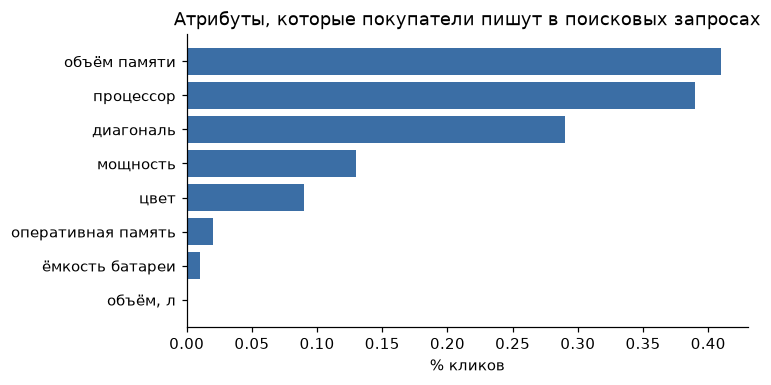

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ad = attr_demand.iloc[::-1]
ax.barh(ad["атрибут"], ad["% кликов из запросов с ним"], color="#3b6ea5")
ax.set_xlabel("% кликов")
ax.set_title("Атрибуты, которые покупатели пишут в поисковых запросах")
save(fig, "attribute_demand")

In [16]:
parts = []
for batch in qc_file.iter_batches(columns=[Q], batch_size=2_000_000):
    lowered = pa.table({"q": pc.utf8_trim_whitespace(pc.utf8_lower(batch.column(0)))})
    parts.append(lowered.group_by("q").aggregate([("q", "count")]))
queries = pa.concat_tables(parts).group_by("q").aggregate([("q_count", "sum")])
del parts
print(f"Уникальных запросов: {queries.num_rows:,}")
top_idx = pc.select_k_unstable(queries, k=25, sort_keys=[("q_count_sum", "descending")])
queries.take(top_idx).to_pandas().set_axis(["запрос", "кликов"], axis=1)

Уникальных запросов: 1,420,991


,запрос,кликов
0,стиральная машинка,571826
1,холодильники,520058
2,аэрогриль,423461
3,микроволновая печь,249633
4,пылесос,248309
5,ноутбук,240516
6,телевизор,239138
7,кондиционер сплит система,227898
8,электрические чайники,227887
9,холодильники двухкамерные,198188


## 4. Связка файлов

Сколько карточек с текстом имеют клики. Пересечение с каталогом `skus.pkl` (а значит, с эталоном
`*_search`) считается в подготовке данных и подтягивается из `data/processed/`, если она уже
прогнана.

In [17]:
click_ids = sku_clicks["sku_id"]
in_clicks = pc.is_in(desc_ids, value_set=click_ids)
n_both = pc.sum(pc.cast(in_clicks, pa.int64())).as_py()
print(f"Карточек с текстом: {len(desc_ids):,}; из них с кликами: {n_both:,} ({n_both / len(desc_ids):.1%})")
print(f"SKU с кликами, но без текста: {sku_clicks.num_rows - n_both:,}")

Карточек с текстом: 1,177,200; из них с кликами: 158,158 (13.4%)
SKU с кликами, но без текста: 174,595


## 5. Каталог и эталон

Разделы ниже читают таблицы из `data/processed/`, которые строит подготовка данных: покрытие
атрибутов эталоном, распределение значений `*_search`, разнобой «продавец ↔ эталон», обязательные
атрибуты по категориям.

In [18]:
processed = sorted(p.name for p in PROCESSED.glob("*")) if PROCESSED.exists() else []
print("data/processed:", processed or "ещё не построено — запустите подготовку данных")

data/processed: ['_offers.parquet', 'categories.parquet', 'clicks_sku.parquet', 'gold.parquet']


## 6. Выводы для пайплайна

Числа — с прогона 2026-10-14 на полном архиве; ячейки выше пересчитывают их при каждом запуске.

1. **Текст есть всегда, но грязный.** Пустых `title`/`description` нет, зато почти половина описаний
   содержит HTML, а у четверти `title` пустая модель («Брелок UNIMALL -»). Препроцессинг: снять HTML,
   не доверять `title` как источнику модели.
2. **Треть атрибутов уже лежит в тексте.** Около 29% описаний содержат блок «Характеристики:»
   и 30% — строки «• ключ: значение». Парсер «ключ: значение» — первая ступень каскада; метрики
   обязательно считаются ещё и на описаниях с вырезанным блоком, иначе хвост не виден.
3. **Нормализация — не косметика.** Только у ключа «цвет» в выборке больше сотни разных записей
   одного базового цвета («черный», «чёрный», «черный матовый», «черное», «black»). Справочник
   канонических значений с алиасами нужен до любой модели.
4. **Трафик сильно сконцентрирован.** Топ-1% SKU собирает 38% кликов, топ-10% — 81%; топ-50
   категорий — 70% кликов, а у 2 341 из 4 103 категорий меньше 100 кликов. Метрики, взвешенные по
   трафику, и средние по карточкам будут сильно расходиться — показываем оба.
5. **Атрибуты редко пишут в запросе.** Запросы в основном категорийные («стиральная машинка»,
   «холодильники»); явное упоминание памяти, процессора, диагонали — доли процента кликов. Вес
   атрибута по одним запросам будет шумным; основной вес — клики категории, упоминания в запросах —
   поправка.
6. **Связка файлов.** Клики есть у 13% карточек с текстом; эталон (`*_search`) — у 241 тыс. карточек
   с текстом (пересечение `skus.pkl` и `sku_desc`), из них ~103 тыс. ещё и с кликами. Этого хватает
   на обучение, валидацию и отложенные категории.